# PS-O3 · 0/1 Knapsack with QAOA — Processor A vs B
**QFF 2026 Phase 1 · SRM University-AP** · `values=[10,4,7,5,8]`, `weights=[5,3,4,2,6]`, `W=15`

**Pipeline:** Knapsack → QUBO (two encodings) → Ising Hamiltonian → QAOA → route on custom Processor A (5q) / B (9q) → noisy benchmark vs brute force.

**Our three ideas on top of the brief**
1. **Unbalanced penalization** – encode `w·x ≤ W` with *no slack qubits* (5 qubits instead of 9) so the problem fits Processor A.
2. **Problem-aware coupling maps** – the QUBO couples *every* pair of qubits, so we design topologies that give the router short paths (bow-tie for A, hub-ring for B).
3. **Practical decoder** – noisy samples are filtered/repaired into a *guaranteed-feasible* packing list.

In [1]:
import os, json, numpy as np, pandas as pd
from IPython.display import display
from src.problem import Knapsack, build_qubo, qubo_to_ising, calibrate_penalty
from src.pipeline import *
from src.processors import *
from src import visualization as viz
np.random.seed(42)
FIG, TAB = 'results/figures/', 'results/tables/'
pd.set_option('display.width', 200, 'display.max_columns', 30)

## 1 · Problem & classical reference (brute force over 2⁵ = 32 subsets)

In [2]:
prob = Knapsack()                      # hardcoded guide values
opt = prob.brute_force()
rows = [dict(items=''.join(map(str, x)), value=v, weight=w, feasible=f) for x, v, w, f in opt['all']]
bf = pd.DataFrame(rows).sort_values('value', ascending=False)
print(f"Optimum: x={opt['best_x']}  value={opt['best_value']}  weight={opt['best_weight']}/{prob.capacity}   "
      f"({opt['n_feasible']}/{opt['n_total']} subsets are feasible)")
display(bf[bf.feasible].head(5))
bf.to_csv(TAB + 'brute_force_all_subsets.csv', index=False)
json.dump(dict(values=prob.values, weights=prob.weights, capacity=prob.capacity, optimum=opt['best_x'], optimum_value=opt['best_value']),
          open('data/raw/instance.json', 'w'), indent=2)

Optimum: x=(1, 1, 1, 1, 0)  value=26  weight=14/15   (28/32 subsets are feasible)


,items,value,weight,feasible
30,11110,26,14,True
21,10101,25,15,True
15,01111,24,15,True
19,10011,23,13,True
22,10110,22,11,True


## 2 · QUBO formulation
Maximise `Σ vᵢxᵢ` s.t. `Σ wᵢxᵢ ≤ W`  ⇒  minimise  `C(x) = −v·x + P(x)`.

| encoding | penalty `P` | qubits |
|---|---|---|
| **slack** (textbook) | `A·(w·x + Σ 2ʲsⱼ − W)²` | 5 + 4 = **9** |
| **unbalanced** (ours) | `λ₁·g + λ₂·g²`, `g = w·x − W` | **5** |

Penalty weights are *calibrated classically*: pick the setting whose ground state is the true optimum with the largest normalised spectral gap. Then `x = (1−Z)/2` turns the QUBO into an Ising Hamiltonian, which we verify against the QUBO cost table.

In [3]:
forms = formulate(prob)
for k, f in forms.items():
    print(f"{k:11s} qubits={f['q'].n}  penalty={f['penalty']}  Pauli terms={len(f['H'])}  H-gap(norm)={f['gap']:.4f}")
print('\nUnbalanced Hamiltonian (Z-basis):'); print(forms['unbalanced']['H'].simplify())
np.save('data/processed/qubo_unbalanced_lin.npy', forms['unbalanced']['q'].lin)
np.save('data/processed/qubo_unbalanced_quad.npy', forms['unbalanced']['q'].quad)
np.save('data/processed/qubo_slack_lin.npy', forms['slack']['q'].lin)
np.save('data/processed/qubo_slack_quad.npy', forms['slack']['q'].quad)

unbalanced  qubits=5  penalty={'l1': 1.75, 'l2': 0.2}  Pauli terms=16  H-gap(norm)=0.0378
slack       qubits=9  penalty={'A': 2.0}  Pauli terms=46  H-gap(norm)=0.0013

Unbalanced Hamiltonian (Z-basis):
SparsePauliOp(['IIIIZ', 'IIIZI', 'IIZII', 'IZIII', 'ZIIII', 'IIIZZ', 'IIZIZ', 'IZIIZ', 'ZIIIZ', 'IIZZI', 'IZIZI', 'ZIIZI', 'IZZII', 'ZIZII', 'ZZIII', 'IIIII'],
              coeffs=[  5.625+0.j,   2.375+0.j,   4.   +0.j,   2.75 +0.j,   4.75 +0.j,
   1.5  +0.j,   2.   +0.j,   1.   +0.j,   3.   +0.j,   1.2  +0.j,
   0.6  +0.j,   1.8  +0.j,   0.8  +0.j,   2.4  +0.j,   1.2  +0.j,
 -16.25 +0.j])


## 3 · Processor A & B — designed from scratch
Reference maps from the guide are kept as **baselines**; our designs are justified by the problem's interaction graph (all-to-all).

,topology,qubits,edges,diameter,avg_degree
0,A_linear (ref),5,4,4,1.60
1,A_tree (ref),5,4,3,1.60
2,A_ring (ours-alt),5,5,2,2.00
3,A_bowtie (ours),5,6,2,2.40
4,B_heavyhex (ref),9,12,4,2.67
5,B_grid (ours-alt),9,12,4,2.67
6,B_wheel (ours),9,16,2,3.56


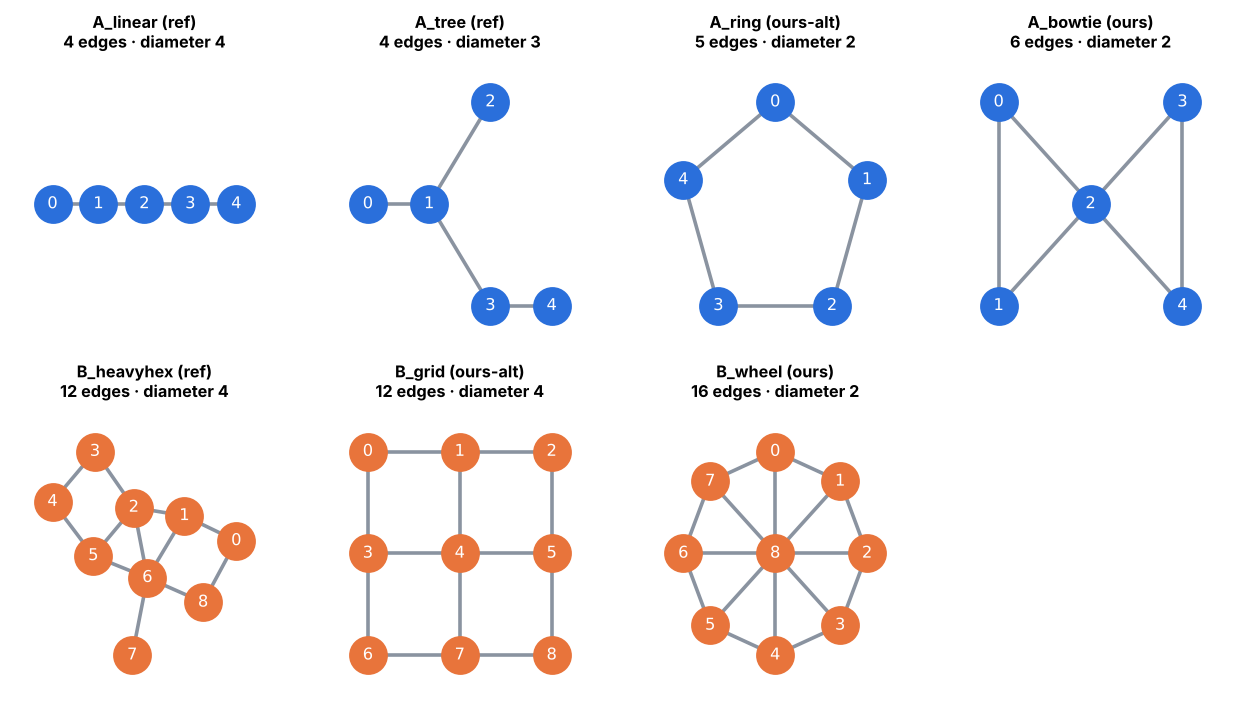

• A_bowtie (ours) → The QUBO penalty (w.x)^2 couples every pair of items (K5). Two triangles sharing a degree-4 hub make 6 of 10 pairs directly adjacent with only 6 edges (diameter 2 vs 4 for a chain).
• B_wheel (ours) → The 9-qubit slack encoding is K9-dense. A ring of 8 plus a hub qubit wired to every ring node has diameter 2; it spends 4 extra edges over heavy-hex (16 vs 12) to cut CX count ~30 %. Trade-off: the hub serialises gates, so circuit depth rises.


In [4]:
export_json('processors')
viz.plot_coupling_maps(list(TOPOLOGIES), FIG + 'coupling_maps.png')
import networkx as nx
topo_tbl = pd.DataFrame([dict(topology=k, qubits=n, edges=len(e), diameter=nx.diameter(coupling_graph(k)),
        avg_degree=round(2*len(e)/n, 2)) for k, (n, e) in TOPOLOGIES.items()])
topo_tbl.to_csv(TAB + 'topologies.csv', index=False); display(topo_tbl)
from IPython.display import Image; display(Image(FIG + 'coupling_maps.png'))
for k, v in RATIONALE.items(): print('•', k, '→', v)

## 4 · QAOA training (exact statevector, COBYLA, linear-ramp + INTERP warm starts)

     ┌───┐                                                                                           »
q_0: ┤ H ├─■─────────────────────────────■─────────────────────────────■─────────────────────────────»
     ├───┤ │ZZ(0.5333333333333333*γ[0])  │                             │                             »
q_1: ┤ H ├─■─────────────────────────────┼─────────────────────────────┼─────────────────────────────»
     ├───┤                               │ZZ(0.7111111111111111*γ[0])  │                             »
q_2: ┤ H ├───────────────────────────────■─────────────────────────────┼─────────────────────────────»
     ├───┤                                                             │ZZ(0.35555555555555557*γ[0]) »
q_3: ┤ H ├─────────────────────────────────────────────────────────────■─────────────────────────────»
     ├───┤                                                                                           »
q_4: ┤ H ├───────────────────────────────────────────────────────────────

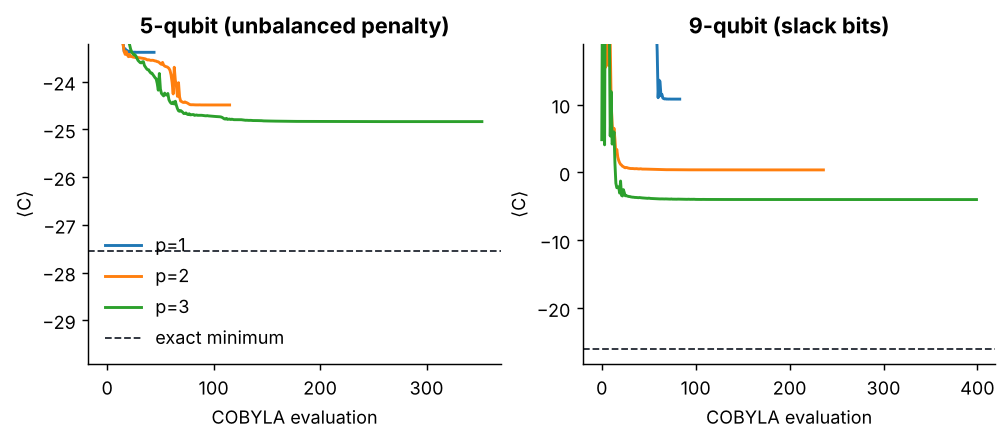

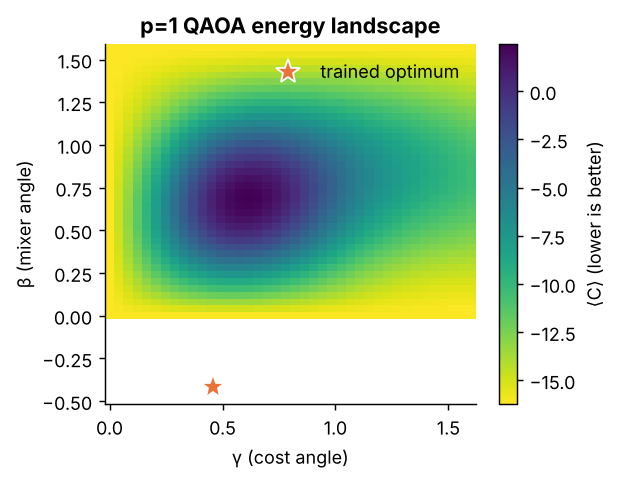

In [5]:
trained = train_all(forms, pmax=3)
print(trained[('unbalanced', 1)]['qaoa'].circuit.draw('text', fold=120))
viz.plot_convergence(trained, FIG + 'convergence.png'); display(Image(FIG + 'convergence.png'))
qa1 = trained[('unbalanced', 1)]['qaoa']; gs, bs, Z = qa1.landscape()
g1, b1 = trained[('unbalanced', 1)]['params']
viz.plot_landscape(gs, bs, Z, FIG + 'landscape_p1.png', (g1, b1)); display(Image(FIG + 'landscape_p1.png'))

## 5 · Ideal (noiseless) quality vs. random guessing, and CVaR objective

In [6]:
iq = ideal_quality(prob, forms, trained, opt)
rb = random_baseline(prob, opt)
print('Random-guess baseline:', {k: round(v, 3) for k, v in rb.items()})
display(iq.round(3)); iq.to_csv(TAB + 'ideal_quality.csv', index=False)
cv = cvar_vs_mean(prob, forms, trained, opt, p=2)
cvt = pd.DataFrame([{k: v for k, v in r.items() if k != 'trace'} for r in cv]); display(cvt.round(3)); cvt.to_csv(TAB + 'cvar_vs_mean.csv', index=False)

Random-guess baseline: {'P(optimal)': 0.031, 'P(feasible)': 0.875, 'E[value | feasible]': 15.143, 'best_sampled_value': 26, 'approx_ratio': 1.0}


,formulation,p,qubits,P(optimal),P(feasible),E[value | feasible],best_sampled_value,approx_ratio,energy,ar_energy
0,unbalanced,1,5,0.102,0.728,21.246,26,1.0,-23.384,0.910
1,unbalanced,2,5,0.217,0.707,22.947,26,1.0,-24.487,0.934
2,unbalanced,3,5,0.226,0.631,23.497,26,1.0,-24.836,0.941
3,slack,1,9,0.024,0.953,14.863,26,1.0,10.814,0.954
4,slack,2,9,0.025,0.964,14.712,26,1.0,0.376,0.967
5,slack,3,9,0.029,0.967,14.757,26,1.0,-3.995,0.972


,objective,P(optimal),P(feasible),E[value | feasible],best_sampled_value,approx_ratio
0,mean energy,0.217,0.707,22.947,26,1.0
1,CVaR α=0.25,0.250,0.682,22.550,26,1.0


## 6 · Processor A vs B benchmark (noisy: 0.1 % 1q, 0.5 % CX, 1 % readout · opt-level 1 · seed 42 · 4096 shots)
Every row is the *same trained circuit* routed onto a different topology, so differences isolate connectivity.

In [7]:
df, store = benchmark(prob, forms, trained, opt, ps=(1, 2, 3))
df.to_csv(TAB + 'benchmark_full.csv', index=False); df.to_json(TAB + 'benchmark_full.json', orient='records', indent=1)
cols = ['formulation','p','processor','depth','cx_count','swaps','cx_overhead','esp','P(optimal)','P(feasible)','approx_ratio','hellinger']
display(df[df.p == 2][['fits'] + cols].round(3))

,fits,formulation,p,processor,depth,cx_count,swaps,cx_overhead,esp,P(optimal),P(feasible),approx_ratio,hellinger
7,True,unbalanced,2,A_linear (ref),112.0,81.0,15.0,41.0,0.582,0.170,0.740,1.0,0.955
8,True,unbalanced,2,A_tree (ref),106.0,70.0,10.0,30.0,0.615,0.172,0.732,1.0,0.955
9,True,unbalanced,2,A_ring (ours-alt),87.0,68.0,10.0,28.0,0.621,0.168,0.731,1.0,0.960
10,True,unbalanced,2,A_bowtie (ours),95.0,52.0,4.0,12.0,0.673,0.183,0.737,1.0,0.967
11,True,unbalanced,2,B_heavyhex (ref),98.0,52.0,4.0,12.0,0.673,0.184,0.726,1.0,0.970
12,True,unbalanced,2,B_grid (ours-alt),101.0,52.0,4.0,12.0,0.673,0.186,0.736,1.0,0.969
13,True,unbalanced,2,B_wheel (ours),87.0,53.0,5.0,13.0,0.670,0.184,0.742,1.0,0.965
28,False,slack,2,A_linear (ref),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
29,False,slack,2,A_tree (ref),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
30,False,slack,2,A_ring (ours-alt),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


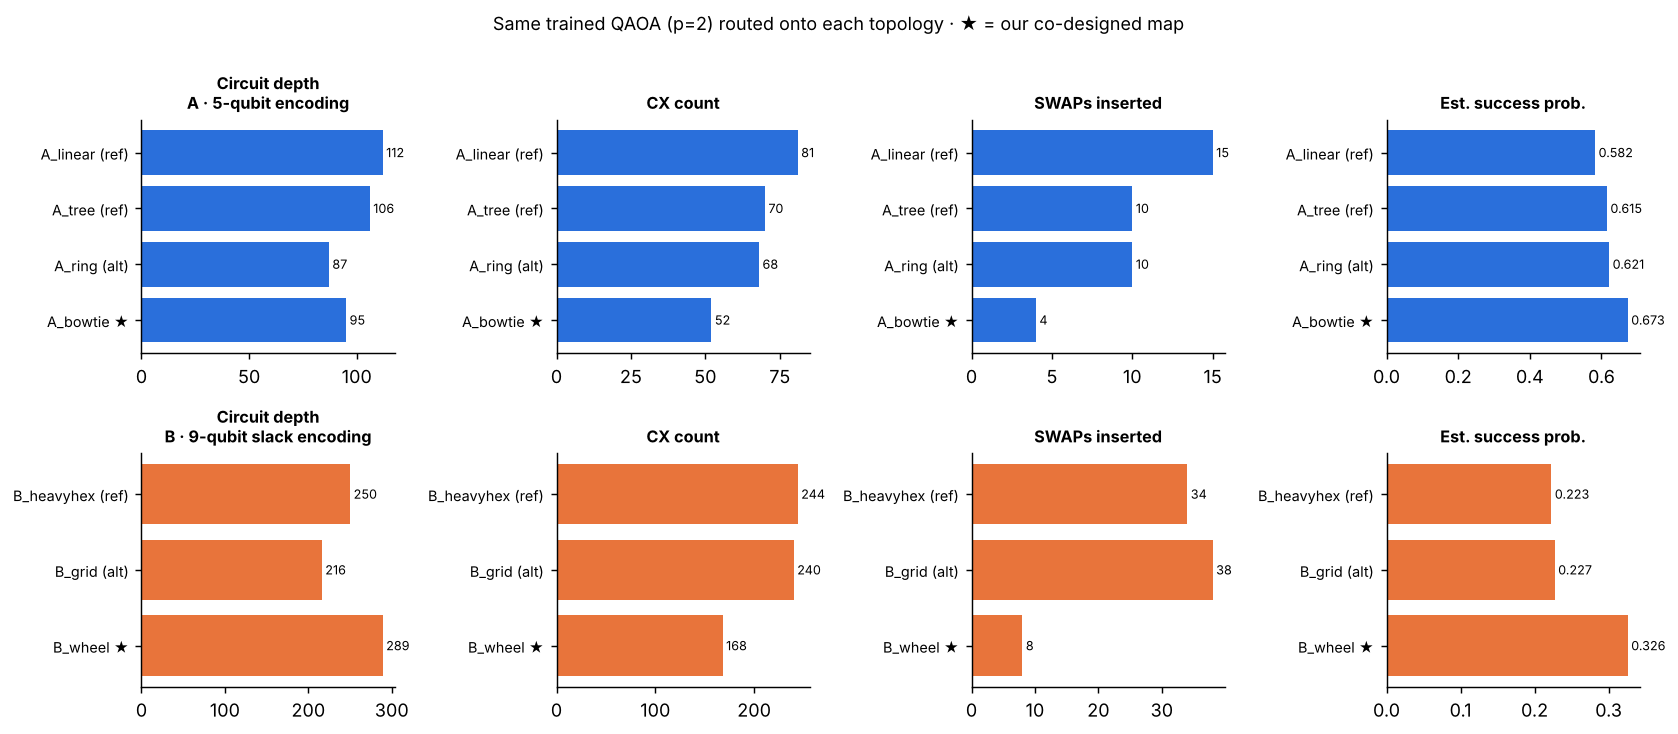

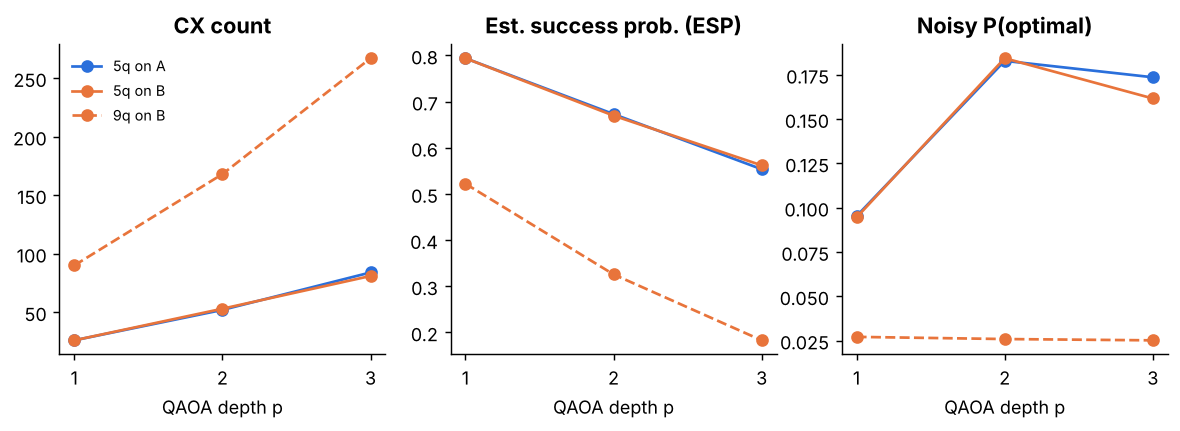

In [8]:
viz.plot_arch(df, FIG + 'architecture_comparison.png', p=2); display(Image(FIG + 'architecture_comparison.png'))
viz.plot_formulations(df, FIG + 'formulation_vs_p.png'); display(Image(FIG + 'formulation_vs_p.png'))

## 6b · Is the routing difference real? 20 transpiler seeds + hardware-cost Pareto
SWAP insertion is stochastic, so one seed can mislead. We re-route the same circuits with 20 seeds (seed 42 stays the official headline).

,processor,cx_mean,cx_std,depth_mean,depth_std,swaps_mean,swaps_std,n_seeds,circuit
0,A_linear (ref),83.3,2.1,112.1,2.5,15.0,0.0,20,5q
1,A_tree (ref),69.8,0.6,107.4,5.5,10.0,0.0,20,5q
2,A_ring (ours-alt),66.9,1.0,86.0,3.9,10.0,0.0,20,5q
3,A_bowtie (ours),52.0,0.0,95.9,2.1,4.0,0.0,20,5q
0,B_heavyhex (ref),240.1,4.5,242.5,18.7,34.2,1.1,20,9q
1,B_grid (ours-alt),253.1,4.3,211.8,13.6,39.3,0.9,20,9q
2,B_wheel (ours),170.1,2.7,284.6,7.1,8.7,0.9,20,9q


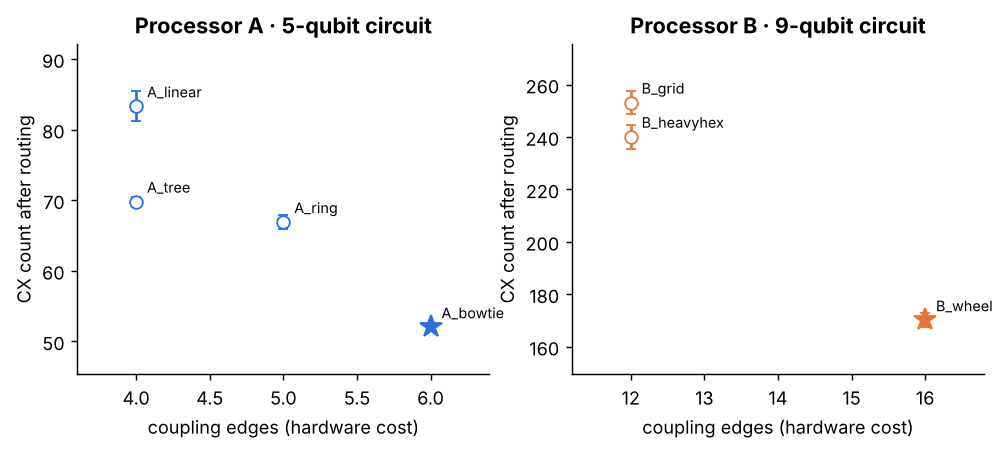

In [9]:
from src.routing import routing_robustness
rob_a = routing_robustness(trained[('unbalanced', 2)]['qaoa'].bound(trained[('unbalanced', 2)]['params']), [t for t in TOPOLOGIES if t.startswith('A')])
rob_b = routing_robustness(trained[('slack', 2)]['qaoa'].bound(trained[('slack', 2)]['params']), [t for t in TOPOLOGIES if t.startswith('B')])
rob = pd.concat([rob_a.assign(circuit='5q'), rob_b.assign(circuit='9q')]); rob.to_csv(TAB + 'routing_robustness_20_seeds.csv', index=False)
display(rob.round(1))
viz.plot_pareto(rob_a, rob_b, FIG + 'edge_budget_vs_cx.png'); display(Image(FIG + 'edge_budget_vs_cx.png'))

## 7 · Noise robustness: how much noise can each processor take?

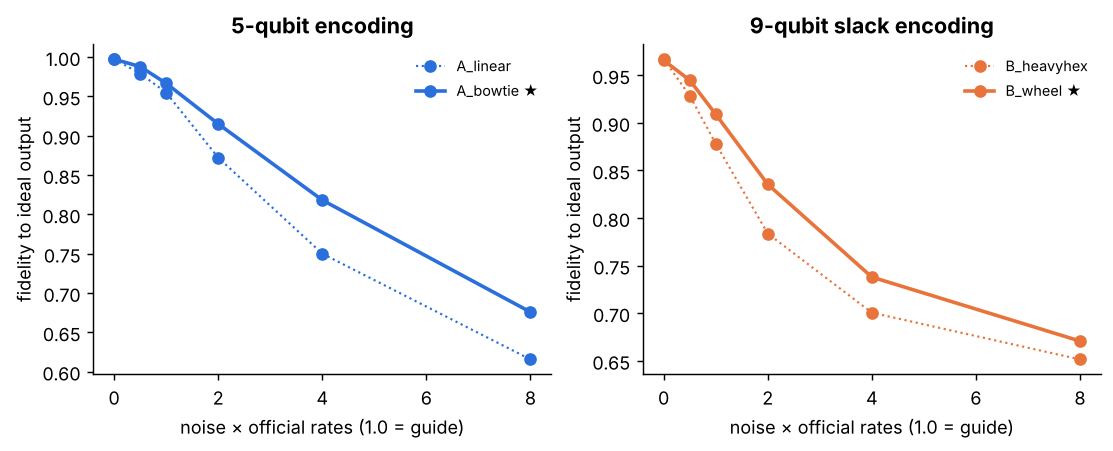

In [10]:
sw = pd.concat([noise_sweep(prob, forms, trained, opt, ['A_linear (ref)', 'A_bowtie (ours)'], kind='unbalanced'),
                noise_sweep(prob, forms, trained, opt, ['B_heavyhex (ref)', 'B_wheel (ours)'], kind='slack')])
sw.to_csv(TAB + 'noise_sweep.csv', index=False)
viz.plot_noise_sweep(sw, FIG + 'noise_sweep.png'); display(Image(FIG + 'noise_sweep.png'))

## 8 · Practical output: what to pack (noisy Processor A run → feasibility filter → repair)

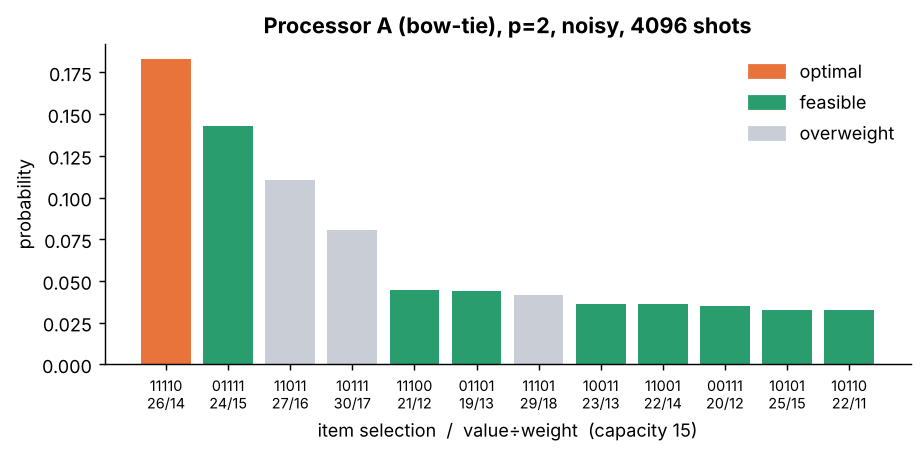

Best feasible sample : (1, 1, 1, 1, 0)  value=26  weight=14/15  -> optimal=True
Most-frequent sample : (1, 1, 1, 1, 0) (feasible)  -> repaired (1, 1, 1, 1, 0)  value=26
Items to pack: [0, 1, 2, 3]


In [11]:
from src.metrics import counts_to_dist
counts = store[('unbalanced', 2, PROCESSOR_A)]
dist = counts_to_dist(counts, 5)
viz.plot_distribution(dist, prob, opt['best_x'], FIG + 'noisy_distribution_A.png', 'Processor A (bow-tie), p=2, noisy, 4096 shots'); display(Image(FIG + 'noisy_distribution_A.png'))
# decoder: best feasible sample; else greedy repair of the most frequent sample
feas = [(prob.evaluate(x)[0], x) for x in dist if prob.is_feasible(x)]
v, x = max(feas)
top = max(dist, key=dist.get); fixed = prob.greedy_repair(top)
print(f"Best feasible sample : {x}  value={v}  weight={prob.evaluate(x)[1]}/{prob.capacity}  -> optimal={x == tuple(opt['best_x'])}")
print(f"Most-frequent sample : {top} {'(feasible)' if prob.is_feasible(top) else '(OVERWEIGHT)'}  -> repaired {fixed}  value={prob.evaluate(fixed)[0]}")
print('Items to pack:', [i for i, b in enumerate(x) if b])

## 9 · Headline results

In [12]:
a = df[(df.p == 2) & (df.formulation == 'unbalanced')].set_index('processor')
s = df[(df.p == 2) & (df.formulation == 'slack') & (df.fits == True)].set_index('processor')
print(f"QAOA p=2 ideal P(optimal)={iq[(iq.formulation=='unbalanced')&(iq.p==2)]['P(optimal)'].iloc[0]:.3f}  vs random {1/32:.3f}  "
      f"(x{iq[(iq.formulation=='unbalanced')&(iq.p==2)]['P(optimal)'].iloc[0]*32:.1f})")
print(f"Bow-tie A vs linear A: SWAPs {a.loc['A_linear (ref)','swaps']:.0f} -> {a.loc['A_bowtie (ours)','swaps']:.0f}, "
      f"CX {a.loc['A_linear (ref)','cx_count']:.0f} -> {a.loc['A_bowtie (ours)','cx_count']:.0f}")
print(f"9-qubit slack encoding on B wheel: CX {s.loc['B_wheel (ours)','cx_count']:.0f} vs 5-qubit {a.loc['A_bowtie (ours)','cx_count']:.0f} on A; "
      f"noisy P(opt) {s.loc['B_wheel (ours)','P(optimal)']:.3f} vs {a.loc['A_bowtie (ours)','P(optimal)']:.3f}")
rb_ = rob_b.set_index('processor')
print(f"Wheel B vs heavy-hex (9q slack, 20-seed mean): CX {rb_.loc['B_heavyhex (ref)','cx_mean']:.0f} -> {rb_.loc['B_wheel (ours)','cx_mean']:.0f}, "
      f"depth {rb_.loc['B_heavyhex (ref)','depth_mean']:.0f} -> {rb_.loc['B_wheel (ours)','depth_mean']:.0f} (trade-off)")

QAOA p=2 ideal P(optimal)=0.217  vs random 0.031  (x6.9)
Bow-tie A vs linear A: SWAPs 15 -> 4, CX 81 -> 52
9-qubit slack encoding on B wheel: CX 168 vs 5-qubit 52 on A; noisy P(opt) 0.026 vs 0.183
Wheel B vs heavy-hex (9q slack, 20-seed mean): CX 240 -> 170, depth 242 -> 285 (trade-off)
